In [1]:
from pathlib import Path
from typing import Final

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
from torch import Tensor

from confidence import evaluate_reject_rule, extract_confidence_data, select_reject_threshold, print_reject_results
from predict import (
    compute_confusion_matrix,
    load_model,
    load_prediction_data,
    print_confusion_matrix,
    print_results,
    run_inference,
)
from profiling import profile_model, print_profile
from train import classification_metrics
from visualisation import plot_embeddings, reduce_embeddings

## Multi-Layer GNN for Facebook Page Classification
### COMP3710 Working Prototype Project in the Era of Artificial Intelligence
#### Derek McKinney (dm-uq)
#### SN: 45506053

### Final Evaluation
<br>
This notebook provides the final comparative evaluation of the frozen MLP baseline and GCN models.<br>
It reuses the project evaluation utilities implemented in predict.py and supporting modules, while providing<br>
additional analysis and interpretation of classification performance, computational cost, confidence behaviour,<br>
learned representations, and representative failure cases.<br>
<br>
References:

Facebook Page-Page dataset:
    https://github.com/gayanku/facebook_page-page_dataset

PyG FacebookPagePage:
    https://pytorch-geometric.readthedocs.io/en/latest/generated/torch_geometric.datasets.FacebookPagePage.html

#### Config and Constants

In [2]:
# constants
SEED: Final[int] = 808

# plot styling
sns.set_theme(context="notebook", style="whitegrid")

# local paths
PROJECT_DIR: Final[Path] = Path.cwd().resolve()
CHECKPOINTS_DIR: Final[Path] = PROJECT_DIR / "checkpoints"
IMAGES_DIR: Final[Path] = PROJECT_DIR / "images" / "evaluation"

MLP_CHECKPOINT: Final[Path] = CHECKPOINTS_DIR / "mlp_final.pt"
GCN_CHECKPOINT: Final[Path] = CHECKPOINTS_DIR / "gcn_final.pt"

In [3]:
# device configuration
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Device: {device}")

if device.type == "cuda":
    print(torch.cuda.get_device_name(0))

Device: cuda
NVIDIA GeForce GTX 950M


#### Frozen Models
Model architectures and hyperparameters were fixed before final test evaluation.<br>
The same stratified 60/20/20 split and seed (808) are used throughout.<br>
The held-out test set has been reserved for final evaluation and was not used in model selection.<br>

| MLP baseline       | GCN                |
|--------------------|--------------------|
| 3 layers           | 4 layers           |
| 128 input features | 128 input features |
| 64 hidden channels | 64 hidden channels |
| 4 output classes   | 4 output classes   |
| ReLU               | ReLU               |
| Dropout: 0.50      | Dropout: 0.55      |
| `mlp_final.pt`     | `gcn_final.pt`     |

#### Load Data and Frozen Models

In [4]:
# load evaluation data
dataset, data = load_prediction_data()

print(data)  # data check

Data(x=[22470, 128], edge_index=[2, 342004], y=[22470], train_mask=[22470], val_mask=[22470], test_mask=[22470])


In [5]:
# Load frozen final models
mlp, _ = load_model(
    model_name="mlp",
    in_channels=data.num_node_features,
    out_channels=dataset.num_classes,
    requested_device=device,
)

gcn, _ = load_model(
    model_name="gcn",
    in_channels=data.num_node_features,
    out_channels=dataset.num_classes,
    requested_device=device,
)

# move graph tensors to evaluation device
data = data.to(device)

print(f"MLP checkpoint: {MLP_CHECKPOINT.name}")  # MLP check
print(f"GCN checkpoint: {GCN_CHECKPOINT.name}")  # GCN check

MLP checkpoint: mlp_final.pt
GCN checkpoint: gcn_final.pt


### Final MLP Baseline Evaluation

In [6]:
# run final MLP inference
mlp_logits = run_inference(
    model=mlp,
    data=data,
)

print(f"MLP logits shape: {mlp_logits.shape}\n")

MLP logits shape: torch.Size([22470, 4])



In [7]:
# compute held-out test metrics
mlp_metrics = classification_metrics(
    logits=mlp_logits,
    labels=data.y,
    mask=data.test_mask,
)

print_results(
    model_name="MLP",
    metrics=mlp_metrics,
)


MLP Aggregate Test Results
--------------------------
Accuracy:         82.24%
Macro Precision:  81.18%
Macro Recall:     79.89%
Macro F1:         80.37%
Macro AUROC:      95.49%

MLP Per-Class Results
--------------------------------------------------------
Class            Precision    Recall        F1   Support
--------------------------------------------------------
tvshow              82.59%    83.99%    83.28%      1299
government          84.01%    85.90%    84.94%      1376
company             83.11%    87.44%    85.22%      1154
politician          75.00%    62.26%    68.04%       665



In [8]:
# generate confusion matrix for held-out test metrics
mlp_confusion = compute_confusion_matrix(
    logits=mlp_logits,
    labels=data.y,
    mask=data.test_mask,
)

print_confusion_matrix(
    model_name="MLP",
    matrix=mlp_confusion,
)


MLP Confusion Matrix
--------------------------------------------------------------
Actual \ Pred.      tvshow  government     company  politician
--------------------------------------------------------------
tvshow                1091          89          28          91
government              65        1182         107          22
company                 17         103        1009          25
politician             148          33          70         414



### Final GCN Evaluation

In [7]:
# run final GCN inference
gcn_logits = run_inference(
    model=gcn,
    data=data,
)

print(f"GCN logits shape: {gcn_logits.shape}\n")

GCN logits shape: torch.Size([22470, 4])



In [10]:
# compute held-out test metrics
gcn_metrics = classification_metrics(
    logits=gcn_logits,
    labels=data.y,
    mask=data.test_mask,
)

print_results(
    model_name="GCN",
    metrics=gcn_metrics,
)


GCN Aggregate Test Results
--------------------------
Accuracy:         95.26%
Macro Precision:  95.02%
Macro Recall:     94.88%
Macro F1:         94.95%
Macro AUROC:      99.25%

GCN Per-Class Results
--------------------------------------------------------
Class            Precision    Recall        F1   Support
--------------------------------------------------------
tvshow              95.25%    94.15%    94.70%      1299
government          95.47%    96.44%    95.95%      1376
company             96.22%    97.05%    96.64%      1154
politician          93.14%    91.88%    92.51%       665



In [11]:
# generate confusion matrix for held-out test metrics
gcn_confusion = compute_confusion_matrix(
    logits=gcn_logits,
    labels=data.y,
    mask=data.test_mask,
)

print_confusion_matrix(
    model_name="GCN",
    matrix=gcn_confusion,
)


GCN Confusion Matrix
--------------------------------------------------------------
Actual \ Pred.      tvshow  government     company  politician
--------------------------------------------------------------
tvshow                1223          32           5          39
government              18        1327          30           1
company                  1          28        1120           5
politician              42           3           9         611



### GCN vs MLP Comparison
The GCN substantially outperformed the feature-only MLP across the held-out test metrics, including macro-F1 and AUROC.<br>
This improvement was also consistent across all four classes, with the largest practical gain occurring for the
comparatively<br>
difficult politician class.<br>

The following analyses examine whether this classification performance increase is accompanied by additional
computational<br>cost, a clearer latent class structure, and an improvement in confidence behaviour.

### Computational Profiling
The frozen MLP and GCN models were profiled under the same hardware and
inference conditions.<br>Parameter count, full-graph inference latency, and peak
PyTorch GPU memory allocation were measured<br>using the profiling functions implemented in `profiling.py`.

#### MLP Profiling

In [6]:
# profile frozen final MLP model
mlp_profile = profile_model(
    model=mlp,
    data=data,
    device=device,
)

In [7]:
# display profiling results for final MLP model
print_profile("MLP", mlp_profile)


MLP Profiling Results
------------------------------
Parameters:         12,676
Mean latency:       2.33 ms
Median latency:     2.30 ms
Peak VRAM:          35.64 MiB



#### GCN Profiling

In [8]:
# profile frozen final GCN model
gcn_profile = profile_model(
    model=gcn,
    data=data,
    device=device,
)

In [9]:
# display profiling results for final GCN model
print_profile("GCN", gcn_profile)


GCN Profiling Results
------------------------------
Parameters:         16,836
Mean latency:       83.49 ms
Median latency:     83.46 ms
Peak VRAM:          225.86 MiB



The GCN contains 16,836 trainable parameters; approximately 33% more than the MLP baseline's 12,676.<br>
The difference in inference cost is much larger - the full-graph latency increases approximately 36x (MLP: 2.33 ms,<br>
GCN: 83.49 ms), while peak PyTorch-allocated GPU memory increases approximately 6.3x (MLP: 35.64 MiB, GCN: 225.86
 MiB).<br>

This reflects the additional graph computation performed by the GCN, where each layer propagates and aggregates<br>
information across neighbouring nodes rather than transforming node features independently.<br>
Despite the relative increases, full-graph GCN inference remains below 0.1 seconds on the local evaluation hardware.

### Embedding Visualisation
The learned representations from the frozen MLP and GCN models were reduced from 64 dimensions to 2 dimensions using<br>
UMAP, providing a qualitative comparison of the class structure captured by each model.<br>

In [10]:
# extract learned node embeddings
mlp.eval()
gcn.eval()

with torch.inference_mode():
    mlp_embeddings = mlp.extract_embeddings(
        data.x,
    )

    gcn_embeddings = gcn.extract_embeddings(
        data.x,
        data.edge_index,
    )

print(f"MLP embeddings: {mlp_embeddings.shape}")
print(f"GCN embeddings: {gcn_embeddings.shape}")

MLP embeddings: torch.Size([22470, 64])
GCN embeddings: torch.Size([22470, 64])


In [13]:
# reduce learned representations to two dimensions
mlp_embedding_2d = reduce_embeddings(
    embeddings=mlp_embeddings,
)

gcn_embedding_2d = reduce_embeddings(
    embeddings=gcn_embeddings,
)

print(f"MLP UMAP: {mlp_embedding_2d.shape}")
print(f"GCN UMAP: {gcn_embedding_2d.shape}")

MLP UMAP: (22470, 2)
GCN UMAP: (22470, 2)


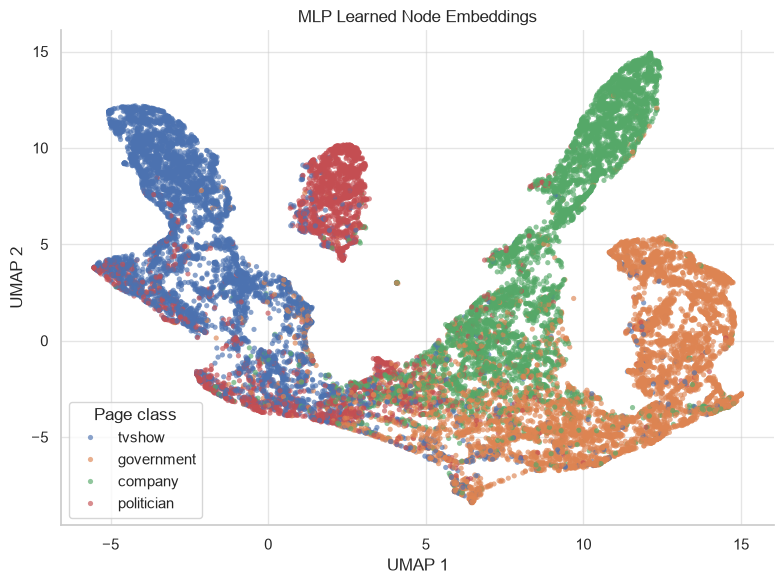

In [17]:
# plot MLP embedding using ground-truth class labels
mlp_figure = plot_embeddings(
    embedding_2d=mlp_embedding_2d,
    labels=data.y,
    model_name="MLP",
)

plt.show()

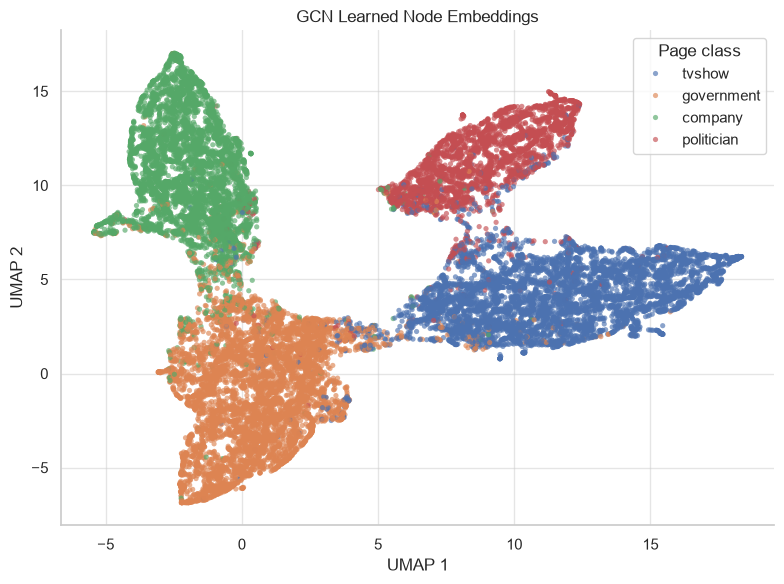

In [18]:
# plot GCN embedding using ground-truth class labels
gcn_figure = plot_embeddings(
    embedding_2d=gcn_embedding_2d,
    labels=data.y,
    model_name="GCN",
)

plt.show()

The UMAP projections reveal a clear difference in the structure learned by the two models.<br>
The MLP embedding shows substantial overlap between classes, particularly between `tvshow` and `politician`,<br>
whereas the GCN embedding forms much more distinct class regions, consistent with its stronger held-out<br>
classification performance.

Note: Ground-truth labels were used only to colour the projected points after dimensionality reduction and<br>
were not provided to UMAP. This preserves the projection as an unsupervised view of the structure present<br>
in the learned representations.

### Confidence and Reject-Option Analysis

Prediction confidence is measured using the maximum softmax response i.e. the largest softmax value assigned<br>
to any class.<br>
A reject-option rule is used to automatically accept high-confidence predictions above a chosen threshold,<br>
while routing lower-confidence cases for human review.

For each model, the global confidence threshold is selected using validation data as the highest confidence<br>
observed among incorrectly classified validation cases. Predictions with confidence greater than this threshold<br>
are automatically accepted. The resulting threshold is then fixed and applied, unchanged, to the test data.

In [8]:
# get validation confidence data for threshold selection
mlp_val_confidence = extract_confidence_data(
    logits=mlp_logits,
    labels=data.y,
    mask=data.val_mask,
)

gcn_val_confidence = extract_confidence_data(
    logits=gcn_logits,
    labels=data.y,
    mask=data.val_mask,
)

#### Choose threshold using validation, only

In [9]:
# select global reject thresholds
MAX_VALIDATION_RISK: Final[float] = 0.01  # threshold: 99%, risk: 1%

mlp_threshold = select_reject_threshold(
    confidence=mlp_val_confidence["confidence"],
    correct=mlp_val_confidence["correct"],
    max_risk=MAX_VALIDATION_RISK,
)

gcn_threshold = select_reject_threshold(
    confidence=gcn_val_confidence["confidence"],
    correct=gcn_val_confidence["correct"],
    max_risk=MAX_VALIDATION_RISK,
)

print(f"MLP threshold: {mlp_threshold:.6f}")
print(f"GCN threshold: {gcn_threshold:.6f}")

MLP threshold: 0.997656
GCN threshold: 0.994863


In [10]:
# evaluate validation coverage and risk at the selected reject thresholds
mlp_val_results = evaluate_reject_rule(
    confidence=mlp_val_confidence["confidence"],
    correct=mlp_val_confidence["correct"],
    threshold=mlp_threshold,
)

gcn_val_results = evaluate_reject_rule(
    confidence=gcn_val_confidence["confidence"],
    correct=gcn_val_confidence["correct"],
    threshold=gcn_threshold,
)

print_reject_results(
    results=mlp_val_results,
    model_name="MLP Validation",
)

print_reject_results(
    results=gcn_val_results,
    model_name="GCN Validation",
)

MLP Validation Reject-Option Results
--------------------------------------
Accepted:                  1,063
Rejected:                  3,431
Accepted errors:              10
Rejected errors:             795
Coverage:                 23.65%
Accepted accuracy:        99.06%
Accepted risk:            0.941%

GCN Validation Reject-Option Results
--------------------------------------
Accepted:                  2,307
Rejected:                  2,187
Accepted errors:              23
Rejected errors:             199
Coverage:                 51.34%
Accepted accuracy:        99.00%
Accepted risk:            0.997%



#### Freeze threshold and apply it to the test

In [11]:
# get test confidence results using selected thresholds
mlp_test_confidence = extract_confidence_data(
    logits=mlp_logits,
    labels=data.y,
    mask=data.test_mask,
)

gcn_test_confidence = extract_confidence_data(
    logits=gcn_logits,
    labels=data.y,
    mask=data.test_mask,
)

In [12]:
# evaluate 'locked' reject-option thresholds on the test set
mlp_test_results = evaluate_reject_rule(
    confidence=mlp_test_confidence["confidence"],
    correct=mlp_test_confidence["correct"],
    threshold=mlp_threshold,
)

gcn_test_results = evaluate_reject_rule(
    confidence=gcn_test_confidence["confidence"],
    correct=gcn_test_confidence["correct"],
    threshold=gcn_threshold,
)

print_reject_results(
    results=mlp_test_results,
    model_name="MLP Test",
)

print_reject_results(
    results=gcn_test_results,
    model_name="GCN Test",
)

MLP Test Reject-Option Results
--------------------------------------
Accepted:                  1,091
Rejected:                  3,403
Accepted errors:              11
Rejected errors:             787
Coverage:                 24.28%
Accepted accuracy:        98.99%
Accepted risk:            1.008%

GCN Test Reject-Option Results
--------------------------------------
Accepted:                  2,264
Rejected:                  2,230
Accepted errors:              21
Rejected errors:             192
Coverage:                 50.38%
Accepted accuracy:        99.07%
Accepted risk:            0.928%



Fin